# Rough metal mirror under oblique illumination — specular and diffuse reflection
A metal half-space ε_m under air ε_o, with a random, non-periodic surface profile: a
Gaussian-correlated height map of given rms height and correlation length. A plane wave
arrives at an angle θ to the mean surface normal, TE or TM. For each polarization three
full-vector Maxwell solves are made: air alone, the flat mirror and the rough mirror.
Subtracting the air field from a mirror field on a plane above the surface leaves the
reflected light alone.

The example shows, for each polarization:
* the total field above the flat and the rough surface, in the plane of incidence;
* the angular spectrum of the reflected light: a single specular spot for the flat
  mirror, a specular remnant plus a diffuse halo for the rough one;
* the flat reflectance against Fresnel, and the share of the rough mirror's reflection
  that stays specular against the Kirchhoff estimate exp(−g), g = (4π σ cos θ / λ)².

The patch is finite with absorbing boundaries on all six faces: one realisation of the
roughness, no periodic repetition of it.

Size: 6 solves, the largest 55.19 Mvoxel including boundaries, 2.88 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from scipy.ndimage import gaussian_filter

from wsutils import plane_wave, apodise, output_dir
from wavesimpro import configure, create_monitor, simulate

NAME = "mx_rough_mirror"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

### Parameters
Lengths in μm. The z axis is depth: light enters at z = 0 and the mirror lies below.

In [2]:
wavelength = 0.5
pixel_size = wavelength / 20
theta_deg = 30.0            # angle of incidence from the mean surface normal, in the x–z plane

eps_o = 1.0                 # air
eps_m = -9.8 + 0.31j        # silver near 500 nm

sim_size = np.array([10.0, 7.0, 1.6])     # x, y, z
z_surface = 1.1             # mean surface depth
rms_height = 0.05           # σ of the height map, λ/10
correlation_length = 0.75   # of the height map, 1.5 λ
seed = 0

z_src = 0.15                # depth of the source sheet
taper = 0.3                 # Tukey taper of the sheet along x and y
boundary_width = 2.0        # absorbing boundary on every face, 4 λ
z_meas = 0.6                # plane where the reflected light is read, between the source and the surface peaks

theta = np.deg2rad(theta_deg)
k0 = 2 * np.pi / wavelength
nx, ny, nz = (int(round(v / pixel_size)) for v in sim_size)
x = (np.arange(nx) + 0.5) * pixel_size
y = (np.arange(ny) + 0.5) * pixel_size
z = (np.arange(nz) + 0.5) * pixel_size
iz_meas = int(z_meas / pixel_size)

g = (4 * np.pi * rms_height * np.cos(theta) / wavelength) ** 2
n_m = np.sqrt(eps_m)
cos_t = np.sqrt(1 - (np.sin(theta) / n_m) ** 2)
fresnel = {"TE": abs((np.cos(theta) - n_m * cos_t) / (np.cos(theta) + n_m * cos_t)) ** 2,
           "TM": abs((n_m * np.cos(theta) - cos_t) / (n_m * np.cos(theta) + cos_t)) ** 2}

print(f"Domain {sim_size} um = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.2f} Mvoxel without boundaries), "
      f"{wavelength / pixel_size:.0f} voxels per vacuum wavelength")
print(f"Mirror eps {eps_m} (n = {n_m:.2f}), skin depth {wavelength / (2 * np.pi * n_m.imag):.3f} um; "
      f"roughness rms {rms_height} um = {rms_height / pixel_size:.1f} voxels, correlation length {correlation_length} um")
print(f"Incidence {theta_deg:.0f} deg: Fresnel R TE {fresnel['TE']:.4f}, TM {fresnel['TM']:.4f}; "
      f"g = {g:.2f}, Kirchhoff specular share exp(-g) = {np.exp(-g):.3f}")

Domain [10.   7.   1.6] um = 400x280x64 voxels (7.17 Mvoxel without boundaries), 20 voxels per vacuum wavelength
Mirror eps (-9.8+0.31j) (n = 0.05+3.13j), skin depth 0.025 um; roughness rms 0.05 um = 2.0 voxels, correlation length 0.75 um
Incidence 30 deg: Fresnel R TE 0.9844, TM 0.9790; g = 1.18, Kirchhoff specular share exp(-g) = 0.306


### Surface and samples
White noise smoothed with a Gaussian kernel gives a height map with correlation
exp(−r²/ℓ²); it is then scaled to the requested rms. The mirror fills every voxel whose
centre lies below the local surface, so the flat mirror is the same build with a zero
height map.

In [3]:
rng = np.random.default_rng(seed)
height = gaussian_filter(rng.standard_normal((nx, ny)), correlation_length / (2 * pixel_size), mode="wrap")
height *= rms_height / height.std()
print(f"Height map: rms {height.std():.4f} um, min {height.min():.3f}, max {height.max():.3f} um")


def build_permittivity(h):
    eps = np.full((nx, ny, nz), eps_o, dtype=np.complex64)
    eps[z[None, None, :] >= (z_surface + h)[:, :, None]] = eps_m
    return eps


eps_air = np.full((nx, ny, nz), eps_o, dtype=np.complex64)
eps_flat = build_permittivity(np.zeros((nx, ny)))
eps_rough = build_permittivity(height)

Height map: rms 0.0500 um, min -0.127, max 0.139 um


### Setup figure
The height map, and a side cut of the rough sample through the domain centre. The
dashed line is the source sheet, the dotted line the read plane, the arrow the incident
direction.

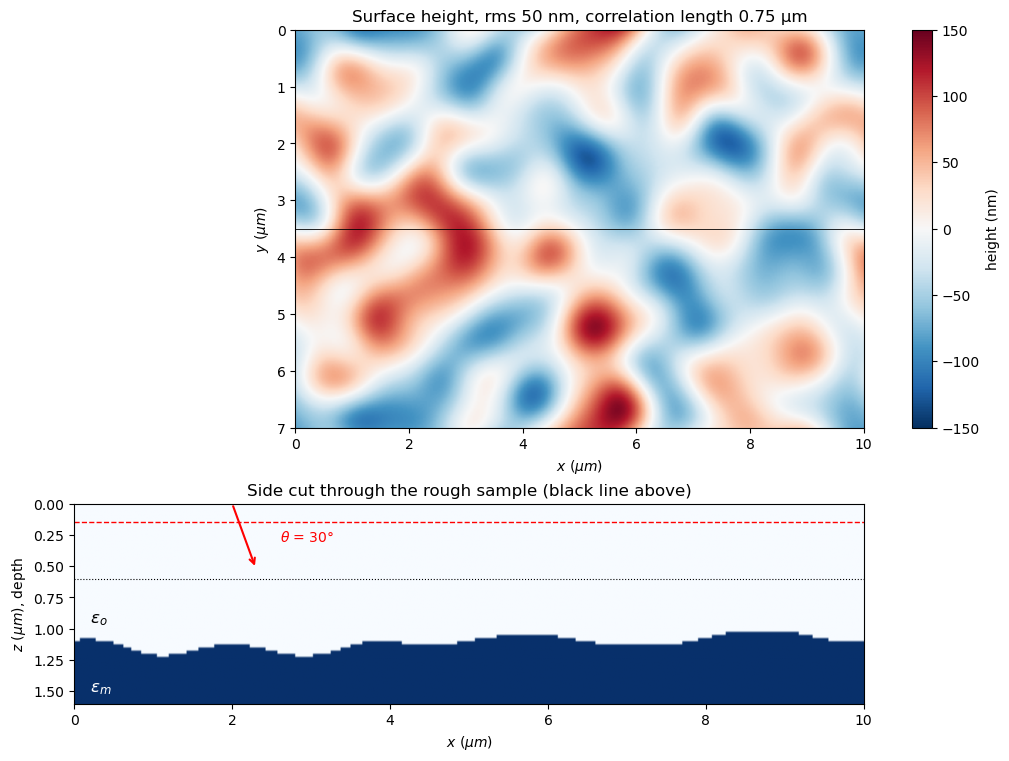

In [4]:
iy_c = ny // 2
extent_xy = [0, sim_size[0], sim_size[1], 0]
extent_xz = [0, sim_size[0], sim_size[2], 0]

fig, (ax_h, ax_s) = plt.subplots(2, 1, figsize=(10, 7.5), constrained_layout=True,
                                 gridspec_kw={"height_ratios": [sim_size[1], 2.2 * sim_size[2]]})
im = ax_h.imshow(1e3 * height.T, cmap="RdBu_r", extent=extent_xy, vmin=-3e3 * rms_height, vmax=3e3 * rms_height)
ax_h.axhline(y[iy_c], color="k", ls="-", lw=0.6)
ax_h.set_xlabel(r"$x~(\mu m)$")
ax_h.set_ylabel(r"$y~(\mu m)$")
ax_h.set_title(f"Surface height, rms {1e3 * rms_height:.0f} nm, correlation length {correlation_length} μm")
fig.colorbar(im, ax=ax_h, fraction=0.03).set_label("height (nm)")
ax_s.imshow(eps_rough[:, iy_c, :].real.T, cmap="Blues_r", extent=extent_xz, vmin=eps_m.real, vmax=eps_o, aspect="auto")
ax_s.axhline(z_src, color="red", ls="--", lw=1)
ax_s.axhline(z_meas, color="k", ls=":", lw=0.8)
ax_s.annotate("", xy=(2 + 0.6 * np.sin(theta), 0.6 * np.cos(theta)), xytext=(2, 0),
              arrowprops=dict(arrowstyle="->", color="red", lw=1.5))
ax_s.text(2.6, 0.3, r"$\theta$ = %g°" % theta_deg, color="red")
ax_s.text(0.2, 0.95, r"$\varepsilon_o$", fontsize=12)
ax_s.text(0.2, 1.5, r"$\varepsilon_m$", fontsize=12, color="white")
ax_s.set_xlabel(r"$x~(\mu m)$")
ax_s.set_ylabel(r"$z~(\mu m)$, depth")
ax_s.set_title("Side cut through the rough sample (black line above)")
fig.savefig(f"{OUTPUT_DIR}/rough_mirror_setup.png", dpi=200)

### Sources
One tilted sheet per polarization, tapered at its edges. TE drives the current along y,
TM along x. A current along x launches a wave whose field is the part of x transverse to
the tilted direction, cos θ of it, so the TM sheet is scaled by 1 / cos θ to give both
polarizations the same incident amplitude.

In [5]:
def make_source(pol):
    axis = {"TE": 1, "TM": 0}[pol]
    values, position = plane_wave(shape=(sim_size[0], sim_size[1]), origin="topleft",
                                  position=(axis, 0.0, 0.0, z_src), source_plane="xy",
                                  pixel_size=pixel_size, theta=theta, wavelength=wavelength)
    if pol == "TM":
        values = values / np.cos(theta)
    return apodise((values, position), axes="xy", alpha=taper)


sources = {pol: make_source(pol) for pol in ("TE", "TM")}

### Solve
Six solves. Each returns only the read plane and the side cut, as two monitors.

In [6]:
def layer_monitor(name, axis, index):
    """The voxel layer ``index`` along ``axis``, over the whole domain. The monitor box is
    half a voxel thick around the layer's centre, so it holds that layer alone; voxel i on
    an n-voxel axis sits at (i + 0.5 - n/2) * pixel_size in domain-centred coordinates."""
    a = "xyz".index(axis)
    centre, extent = [0.0, 0.0, 0.0], [n * pixel_size for n in (nx, ny, nz)]
    centre[a] = (index + 0.5 - (nx, ny, nz)[a] / 2) * pixel_size
    extent[a] = pixel_size / 2
    return create_monitor(name=name, center_x=centre[0], center_y=centre[1], center_z=centre[2],
                          size_x=extent[0], size_y=extent[1], size_z=extent[2])


monitors = [layer_monitor("plane", "z", iz_meas), layer_monitor("side", "y", iy_c)]


def solve(eps, source):
    start = time()
    (plane, side), iterations, residual = simulate(
        permittivity=eps, sources=[source], wavelength=wavelength, pixel_size=pixel_size,
        boundary_width=boundary_width, periodic=(False, False, False), monitors=monitors)
    print(f"  {time() - start:.1f} s, {iterations} iterations, residual {residual:.1e}")
    return {"plane": plane.reshape(3, nx, ny), "side": np.sqrt(np.sum(np.abs(side.reshape(3, nx, nz)) ** 2, axis=0))}


fields = {}
for pol in ("TE", "TM"):
    for case, eps in (("air", eps_air), ("flat", eps_flat), ("rough", eps_rough)):
        print(f"{pol}: {case}")
        fields[pol, case] = solve(eps, sources[pol])
np.savez(f"{OUTPUT_DIR}/rough_mirror_fields.npz",
         **{f"{pol}_{case}_{k}": v for (pol, case), f in fields.items() for k, v in f.items()})

TE: air

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 3110172f-9252-42db-8a2b-c3e6092b359b
  Version   : 63b559b0-35ef-4b5c-8b1c-3c8cd5187d55
  Command   : f54a220a-0e08-4c82-b41d-86cf7084f493
  Mode      : Maxwell (vectorial)
  Domain    : 400x280x64 voxels  lambda=0.5 um  dx=0.025 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  44.2 s, 71 iterations, residual 6.7e-07
TE: flat

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 469b9e74-0d3a-4c1b-b3a2-6fe15e0f32d5
  Version   : 78dde90a-3db1-4900-a3fd-74d5b4412bbd
  Command   : 519d6bd7-9170-4cb1-ac5b-e56497837a07
  Mode      : Maxwell (vectorial)
  Domain    : 400x280x64 voxels  lambda=0.5 um  dx=0.025 um
  Engine    : Any (a

### Figure 1: total field in the plane of incidence
|E| above the flat and the rough mirror, TE, down to just below the deepest valley; the
metal is drawn grey. The incident and reflected waves interfere into the tilted
standing-wave pattern; over the rough surface the pattern breaks up.

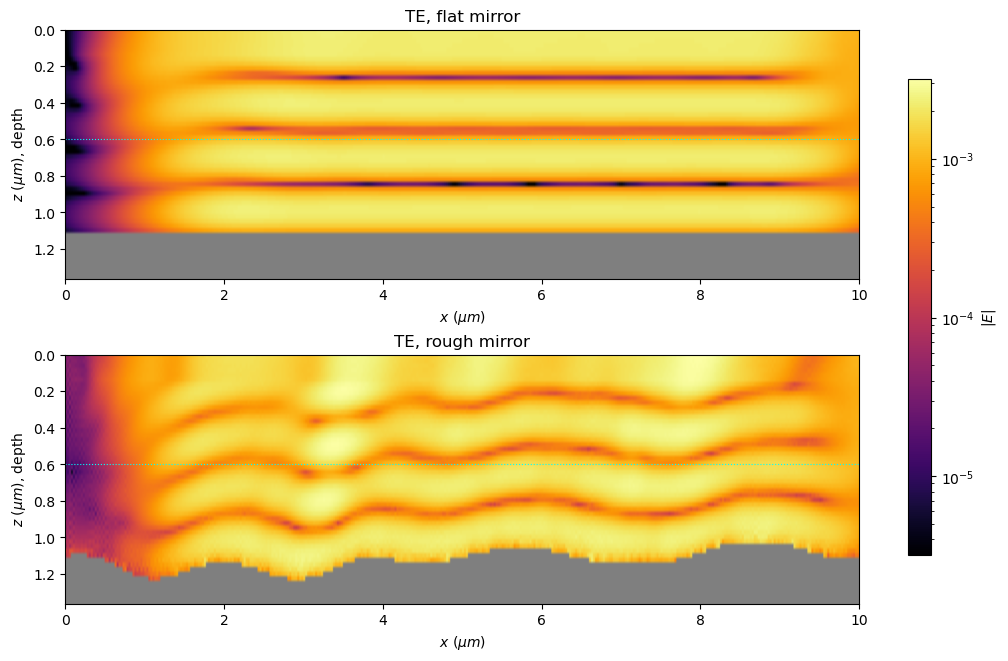

In [7]:
iz_cut = int((z_surface + 0.25) / pixel_size)
vmax = max(fields["TE", "flat"]["side"].max(), fields["TE", "rough"]["side"].max())
cmap = plt.get_cmap("inferno").with_extremes(bad="0.5")
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), constrained_layout=True)
for ax, case, eps in zip(axes, ("flat", "rough"), (eps_flat, eps_rough)):
    side = np.where(eps[:, iy_c, :iz_cut] == eps_m, np.nan, fields["TE", case]["side"][:, :iz_cut])
    im = ax.imshow(side.T, cmap=cmap, aspect="auto",
                   extent=[0, sim_size[0], z[iz_cut], 0], norm=colors.LogNorm(vmin=vmax * 1e-3, vmax=vmax))
    ax.axhline(z_meas, color="cyan", ls=":", lw=0.8)
    ax.set_title(f"TE, {case} mirror")
    ax.set_xlabel(r"$x~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$, depth")
fig.colorbar(im, ax=axes, fraction=0.03).set_label(r"$|E|$")
fig.savefig(f"{OUTPUT_DIR}/rough_mirror_field.png", dpi=200)

### Figure 2: angular spectrum of the reflected light
The reflected field on the read plane, Fourier transformed along x and y: intensity
against the direction cosines of the waves travelling back up, on a log scale over four
decades. The cross marks the specular direction.

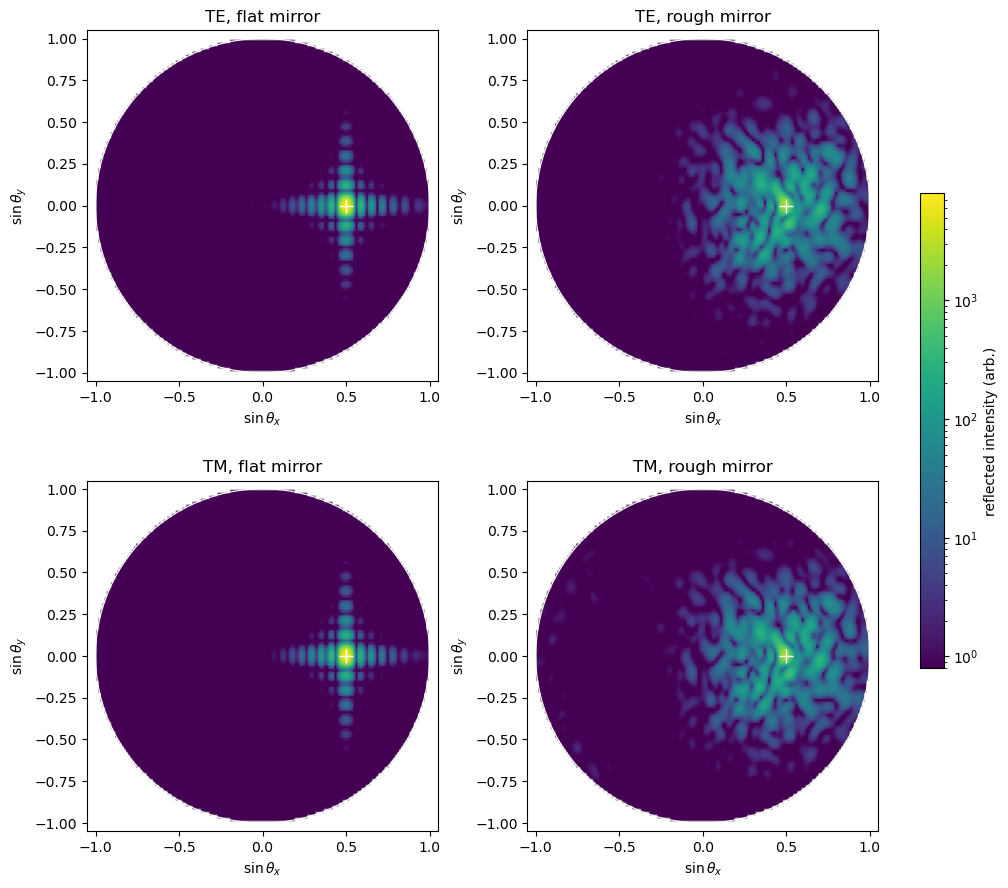

In [8]:
pad = 4                                       # zero-padding factor for a smoother spectrum
kx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(pad * nx, pixel_size)) / k0
ky = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(pad * ny, pixel_size)) / k0
propagating = (kx[:, None] ** 2 + ky[None, :] ** 2) < 1
cos_k = np.sqrt(np.where(propagating, 1 - kx[:, None] ** 2 - ky[None, :] ** 2, 0))


def angular_spectrum(u_plane):
    spectrum = np.fft.fftshift(np.fft.fft2(u_plane, s=(pad * nx, pad * ny), axes=(1, 2)), axes=(1, 2))
    return np.where(propagating, np.sum(np.abs(spectrum) ** 2, axis=0), np.nan)


def power(spectrum):
    """Flux through the plane: each propagating wave's intensity weighted by the cosine of its direction."""
    return np.nansum(spectrum * cos_k)


reflected = {(pol, case): fields[pol, case]["plane"] - fields[pol, "air"]["plane"]
             for pol in ("TE", "TM") for case in ("flat", "rough")}
spectra = {key: angular_spectrum(u) for key, u in reflected.items()}
smax = max(np.nanmax(s) for s in spectra.values())
extent_k = [kx[0], kx[-1], ky[-1], ky[0]]

fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
for row, pol in zip(axes, ("TE", "TM")):
    for ax, case in zip(row, ("flat", "rough")):
        im = ax.imshow(spectra[pol, case].T, cmap="viridis", extent=extent_k,
                       norm=colors.LogNorm(vmin=smax * 1e-4, vmax=smax))
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, ec="white", lw=0.8))
        ax.plot(np.sin(theta), 0, "w+", ms=10)
        ax.set_xlim(-1.05, 1.05)
        ax.set_ylim(-1.05, 1.05)
        ax.set_xlabel(r"$\sin\theta_x$")
        ax.set_ylabel(r"$\sin\theta_y$")
        ax.set_title(f"{pol}, {case} mirror")
fig.colorbar(im, ax=axes, fraction=0.03).set_label("reflected intensity (arb.)")
fig.savefig(f"{OUTPUT_DIR}/rough_mirror_angular.png", dpi=200)

### Reflectance and specular share
Reflectance is the reflected flux through the read plane over the incident flux, both
from the angular spectra. The specular share of the rough mirror's reflection is the
part of its flux falling inside the flat mirror's specular spot, taken as the region
where the flat spectrum exceeds 1 % of its peak.

In [9]:
print(f"\n{'':4s} {'R flat':>8s} {'Fresnel':>8s} {'R rough':>8s} {'specular':>9s} {'exp(-g)':>8s}")
for pol in ("TE", "TM"):
    p_inc = power(angular_spectrum(fields[pol, "air"]["plane"]))
    r_flat = power(spectra[pol, "flat"]) / p_inc
    r_rough = power(spectra[pol, "rough"]) / p_inc
    spot = spectra[pol, "flat"] > 0.01 * np.nanmax(spectra[pol, "flat"])
    specular = power(np.where(spot, spectra[pol, "rough"], 0)) / power(spectra[pol, "rough"])
    print(f"{pol:4s} {r_flat:8.4f} {fresnel[pol]:8.4f} {r_rough:8.4f} {specular:9.3f} {np.exp(-g):8.3f}")
print(f"Saved output/{NAME}/rough_mirror_setup.png, _field.png, _angular.png")

plt.show()


       R flat  Fresnel  R rough  specular  exp(-g)
TE     0.9770   0.9844   0.9480     0.348    0.306
TM     0.9655   0.9790   0.9067     0.341    0.306
Saved output/mx_rough_mirror/rough_mirror_setup.png, _field.png, _angular.png
